# Velocity-binned J·E
Adapted from PS_2D.ipynb: same ion-velocity coordinates (M=y, N=x), percentile trimming, independent energy-conversion normalization, and color limits. Reads existing JiE, JeE, and JE from JE.nc and plots one row of three panels.

Each field is independently divided by its maximum absolute value after percentile trimming, as in the pressure–strain notebook. Colors therefore compare patterns rather than absolute species amplitudes.

In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from turbos.sim.vpic.vpic import VPIC
from turbos.filter import kfilter

In [14]:
from turbos.sim.vpic.vpic import VPIC

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

In [15]:
JE_PATH = Path("~/turbos/projects/KHI_2D/data/JE.nc").expanduser()
ds_JE = xr.open_dataset(JE_PATH)
print(ds_JE)

fields = ["JiE", "JeE", "JE"]  # Flat list: each selection is a DataArray.
missing = set(fields) - set(ds_JE.data_vars)
if missing:
    raise KeyError(f"Missing variables in JE.nc: {sorted(missing)}")

# Use the filter setting stored with the energy-conversion fields.
# If the attribute is absent, set kf explicitly here.
kf = ds_JE.attrs.get("kf")
if kf is None:
    raise ValueError("JE.nc has no kf attribute; set kf explicitly.")

fallback_steps = [140000, 240000, 320000, 480000]
if "step" in ds_JE.coords:
    saved_steps = np.asarray(ds_JE["step"].values)
    if not np.all(np.isfinite(saved_steps)) or not np.all(saved_steps == saved_steps.astype(int)):
        raise ValueError("Saved steps must be finite integers.")
    times = saved_steps.astype(int)
else:
    times = np.asarray(fallback_steps)
if len(times) != ds_JE.sizes["time"]:
    raise ValueError("Need one VPIC step for each time in JE.nc.")

stride = 8
bins = 40
min_count = 5
percentile = (1, 99)  # Same trimming as PS_2D; None retains all finite samples.
print(f"Loading steps {times.tolist()}, kf={kf}, stride={stride}")

<xarray.Dataset> Size: 138MB
Dimensions:          (time: 4, x: 1200, y: 2400)
Coordinates:
  * time             (time) float64 32B 41.25 70.71 94.28 141.4
    time_simulation  (time) float64 32B ...
    step             (time) int64 32B ...
  * x                (x) float64 10kB 0.0 0.1042 0.2083 ... 124.7 124.8 124.9
  * y                (y) float64 19kB 0.0 0.1042 0.2083 ... 249.7 249.8 249.9
Data variables:
    JiE              (time, x, y) float32 46MB ...
    JeE              (time, x, y) float32 46MB ...
    JE               (time, x, y) float32 46MB ...
Attributes:
    kf:       4
Loading steps [140000, 240000, 320000, 480000], kf=4, stride=8


In [16]:
def component(da, name):
    """Select vector component without retaining scalar coordinates."""
    dim = next(d for d in ("c", "comp") if d in da.dims)
    if name in da[dim].values:
        return da.sel({dim: name}, drop=True)
    return da.isel({dim: {"x": 0, "y": 1, "z": 2}[name]}, drop=True)


velocities = []
for index, ti in enumerate(times):
    ds = run.load_step(int(ti), ["ui"])
    if "step" in ds.attrs and int(ds.attrs["step"]) != int(ti):
        raise ValueError("Loaded velocity step does not match JE step.")
    if "time_simulation" in ds_JE.coords and "time_simulation" in ds.attrs:
        if not np.isclose(float(ds_JE.time_simulation.isel(time=index)),
                          ds.attrs["time_simulation"], rtol=1e-5):
            raise ValueError("Velocity and JE simulation times do not match.")
    # Filter full-resolution velocity before spatial subsampling.
    ui = kfilter(ds["ui"], kf)
    ui, _ = xr.align(ui, ds_JE["JE"].isel(time=index, drop=True),
                     join="exact", copy=False)
    ds_v_step = xr.Dataset({
        "V_M": component(ui, "y"),
        "V_N": component(ui, "x"),
    }).isel(x=slice(None, None, stride), y=slice(None, None, stride))
    velocities.append(ds_v_step.expand_dims(
        time=[ds_JE.time.values[index]]
    ).load())

ds_v = xr.concat(velocities, dim="time", join="exact")
print(ds_v)

<xarray.Dataset> Size: 1MB
Dimensions:  (time: 4, x: 150, y: 300)
Coordinates:
  * time     (time) float64 32B 41.25 70.71 94.28 141.4
  * x        (x) float64 1kB 0.0 0.8333 1.667 2.5 ... 121.7 122.5 123.3 124.2
  * y        (y) float64 2kB 0.0 0.8333 1.667 2.5 ... 246.7 247.5 248.3 249.2
Data variables:
    V_M      (time, x, y) float32 720kB -0.003621 -0.003436 ... 0.02731 0.02732
    V_N      (time, x, y) float32 720kB -5.681e-05 -0.0002174 ... -0.0001242


In [17]:
def velocity_binned_mean(
    vM, vN, Q,
    bins=40,
    min_count=5,
    percentile=(1, 99)
):
    vM = np.asarray(vM, dtype=float).ravel()
    vN = np.asarray(vN, dtype=float).ravel()
    Q = np.asarray(Q, dtype=float).ravel()

    if not (vM.shape == vN.shape == Q.shape):
        raise ValueError(f"Sample shape mismatch: {vM.shape}, {vN.shape}, {Q.shape}")

    # Remove invalid data
    valid = (
        np.isfinite(vM)
        & np.isfinite(vN)
        & np.isfinite(Q)
    )

    vM = vM[valid]
    vN = vN[valid]
    Q = Q[valid]

    if len(Q) == 0:
        raise ValueError("No finite samples available")

    # Remove event-average velocity
    vM = vM - np.mean(vM)
    vN = vN - np.mean(vN)

    # Normalize each velocity coordinate
    vM /= max(np.max(np.abs(vM)), np.finfo(float).tiny)
    vN /= max(np.max(np.abs(vN)), np.finfo(float).tiny)

    # Same percentile trimming as the pressure-strain notebook.
    # if percentile is not None:
    #     qlo, qhi = np.percentile(Q, percentile)
    #     keep = (Q >= qlo) & (Q <= qhi)
    #     vM, vN, Q = vM[keep], vN[keep], Q[keep]
    # if Q.size == 0:
    #     raise ValueError("No samples remain after percentile trimming")

    # Normalize energy conversion
    Q = Q / max(np.max(np.abs(Q)), np.finfo(float).tiny)

    edges = np.linspace(-1, 1, bins + 1)

    counts, _, _ = np.histogram2d(
        vM, vN, bins=[edges, edges]
    )

    weighted, _, _ = np.histogram2d(
        vM, vN,
        bins=[edges, edges],
        weights=Q
    )

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_Q = weighted / counts

    mean_Q[counts < min_count] = np.nan

    return edges, mean_Q.T, counts.T

In [18]:
time_idx = 3  # 0, 1, 2, or 3; -1 selects the last snapshot.

vM = ds_v["V_M"].isel(time=time_idx).transpose("x", "y").values.ravel()
vN = ds_v["V_N"].isel(time=time_idx).transpose("x", "y").values.ravel()


def get_samples(var):
    return ds_JE[var].isel(
        time=time_idx,
        x=slice(None, None, stride),
        y=slice(None, None, stride),
    ).transpose("x", "y").values.ravel()


print("vM:", vM.shape)
print("vN:", vN.shape)
for var in fields:
    samples = get_samples(var)
    if samples.shape != vM.shape or samples.shape != vN.shape:
        raise ValueError(f"Velocity and {var} sample shapes differ")
    print(f"{var}:", samples.shape)

vM: (45000,)
vN: (45000,)
JiE: (45000,)
JeE: (45000,)
JE: (45000,)


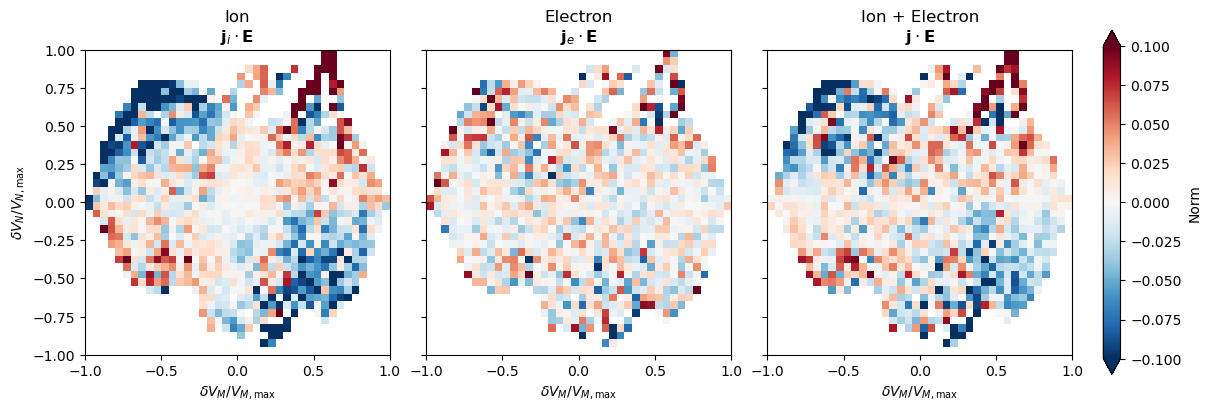

In [20]:
fig, ax = plt.subplots(
    1, 3,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
    layout="constrained",
)

titles = ["Ion", "Electron", "Ion + Electron"]
term_labels = [
    r"$\mathbf{j}_i\cdot\mathbf{E}$",
    r"$\mathbf{j}_e\cdot\mathbf{E}$",
    r"$\mathbf{j}\cdot\mathbf{E}$",
]
norm = TwoSlopeNorm(vcenter=0, vmin=-1e-1, vmax=1e-1)
binned_results = {}

for col, var in enumerate(fields):
    edges, Qmean, counts = velocity_binned_mean(
        vM, vN, get_samples(var),
        bins=bins,
        min_count=min_count,
        percentile=percentile,
    )
    binned_results[var] = {"edges": edges, "mean": Qmean, "counts": counts}
    im = ax[col].pcolormesh(
        edges, edges, Qmean,
        cmap="RdBu_r", norm=norm, shading="auto",
    )
    ax[col].set_aspect("equal")
    ax[col].set_title(titles[col] + "\n" + term_labels[col])
    ax[col].set_xlabel(r"$\delta V_M / V_{M,\max}$")

ax[0].set_ylabel(r"$\delta V_N / V_{N,\max}$")
cbar = fig.colorbar(
    im, ax=ax, location="right", fraction=0.025, pad=0.02, shrink=0.7,
    extend="both",
)
cbar.set_label(r"Norm")
fig.savefig("/home/2480/turbos/projects/KHI_2D/fig/JE_2D_nl.png", dpi=300, bbox_inches="tight")
plt.show()